# 02 PyTorch张量操作与自动微分


本篇对应 **day02**，是「06-深度学习神经网络」7篇笔记中的第2篇。承接01的张量创建与类型转换，继续学习张量与NumPy互转、数值运算、索引、形状变换、拼接，以及自动微分和参数更新。

资料：[深度学习神经网络课程资料](https://pan.baidu.com/s/1FPhKS2qMBgnqVOXCyhBTog?pwd=1234)，提取码 `1234`。已核对 `04_深度学习神经网络/视频/day02` 的 **16个视频文件标题**；其中内容大纲和上午回顾融入学习路线与复习，其余主题均有对应章节。

原 `课堂笔记.zip` 和 `课件.zip` 的正文未取得，视频未逐段转录。本篇按核对后的目录组织，解释、数据和代码为独立编写，不能视为教师原文。示例按顺序复制到代码单元即可运行，全部示意图直接内嵌在当前Notebook中。


## 本篇学习路线

| 阶段 | 对应视频 | 要掌握的能力 |
| --- | --- | --- |
| 数据互通 | 02 | 识别NumPy和Tensor是否共享内存 |
| 运算与索引 | 03—07 | 区分逐元素乘、向量内积、矩阵乘；按轴统计和取数据 |
| 形状与拼接 | 09—13 | 区分重新分组、交换轴、增删轴和合并张量 |
| 自动微分 | 14—16 | 计算梯度，更新一次参数，再循环更新 |

上一篇会创建张量，本篇要能回答两个问题：**每一步的shape是多少？这一步是否影响原始数据或计算图？**

自动微分部分使用简单的一元目标函数，把更新流程讲清楚。完整线性回归、神经网络和激活函数留给第3篇。


## 1. 环境准备与约定

本篇使用 `torch` 和 `numpy`，CPU即可运行，不需要训练数据或GPU。代码块按顺序执行，后文复用 `torch`、`np`。

```bash
python -m pip install torch numpy
```

```python
import torch
import numpy as np

torch.manual_seed(2026)
print("PyTorch:", torch.__version__)
print("NumPy:", np.__version__)
print("device: CPU")
```

所有例子显式使用CPU。随机示例固定种子便于同一环境下复现，跨版本和设备不保证逐位一致。


## 2. NumPy转Tensor：复制还是共享

NumPy的 `ndarray` 常用于数据分析，PyTorch的 `Tensor` 支持自动微分和不同计算设备。转换时除了shape和dtype，还要关注**内存关系**。

| 写法 | 常见行为 | 适用场景 |
| --- | --- | --- |
| `torch.tensor(arr)` | 复制数据 | 希望张量独立于原数组 |
| `torch.from_numpy(arr)` | 共享支持类型的CPU数组内存 | 尽量避免复制 |
| `torch.as_tensor(arr)` | 条件允许时共享；类型或设备变化可能复制 | 尽量保留现有数据 |

下面分别修改Tensor和NumPy数组，观察共享与独立的区别。

```python
arr = np.array([1.0, 2.0, 3.0], dtype=np.float32)
shared = torch.from_numpy(arr)
copied = torch.tensor(arr)
adapted = torch.as_tensor(arr)

shared[0] = 10.0
arr[1] = 20.0
print("NumPy:", arr)           # [10. 20.  3.]
print("shared:", shared)       # tensor([10., 20., 3.])
print("adapted:", adapted)     # 同样跟着改变
print("copied:", copied)       # tensor([1., 2., 3.])
assert np.shares_memory(arr, shared.numpy())
assert not np.shares_memory(arr, copied.numpy())
```

共享转换支持的dtype和布局有要求，不是任意数组都能零复制。遇到负步长，例如 `arr[::-1]`，可先 `arr[::-1].copy()`；对只读数组先复制成可写数组，再构建需要修改的Tensor。不要把“转换函数”一律理解成“新建独立副本”。


## 3. Tensor转NumPy与Python值

对于不需要梯度、dtype和布局受支持的CPU张量，`tensor.numpy()` 通常共享存储。GPU张量要先移到CPU；需要梯度的张量要先与计算图分离。

常见导出写法是 `tensor.detach().cpu().numpy()`。注意：`detach()` 不复制存储，`cpu()` 对已经在CPU的张量也可能直接返回原对象，所以这串操作**不保证数据独立**。如果准备交给会修改数组的代码，末尾再加 `.copy()`。

```python
cpu_tensor = torch.tensor([1.0, 2.0, 3.0])
numpy_view = cpu_tensor.numpy()
numpy_view[0] = 99.0
assert cpu_tensor[0].item() == 99.0

tracked = torch.tensor([2.0, 4.0], requires_grad=True)
exported = tracked.detach().cpu().numpy().copy()
exported[0] = -10.0
assert tracked[0].item() == 2.0

one_value = torch.tensor(3.5).item()
many_values = torch.tensor([[1, 2], [3, 4]]).tolist()
print(one_value, type(one_value))  # 3.5, float
print(many_values)                 # [[1, 2], [3, 4]]
```

`item()` 只用于单元素张量，返回Python数字；`tolist()` 返回嵌套列表。两者导出的是Python值，不保留自动微分链路，不能把它们用于需要求导的中间计算。


## 4. 基本运算与原地修改

`+、-、*、/` 默认逐元素运算，也可使用 `torch.add、sub、mul、div`。形状不同但可广播时仍能计算。

```python
a = torch.tensor([2.0, 4.0, 8.0])
b = torch.tensor([1.0, 2.0, 4.0])
print(a + b)       # [3., 6., 12.]
print(a - b)       # [1., 2., 4.]
print(a * b)       # [2., 8., 32.]
print(a / b)       # [2., 2., 2.]
print(a ** 2)      # [4., 16., 64.]

original = torch.tensor([1.0, 2.0])
new_result = original.add(10)
assert original.tolist() == [1.0, 2.0]
original.add_(10)
assert original.tolist() == [11.0, 12.0]
print(new_result, original)
```

方法名结尾带 `_`，例如 `add_、mul_`，通常表示**原地修改**。`x += y` 也通常在原地更新。`x = x + y` 则把变量重新绑定到新结果。

内存共享的对象会受原地修改影响，某些原地修改还会破坏反向传播所需的值。初学自动微分时，计算过程优先用普通运算；参数更新放在 `torch.no_grad()` 中。除法不会因为两边是整数就自动得到整数商，也不要对零分母直接运算。


## 5. 广播：从右向左对齐shape

广播让一个较小张量参与较大张量的逐元素运算，例如给每个样本加同一组特征偏置。

规则是：**从最右侧轴开始对齐，两个维度相等，或其中一个为1，或某一侧缺少该维度，才能兼容。** 长度为1的维度可以被扩展；广播通常不需要先真正复制成大矩阵。

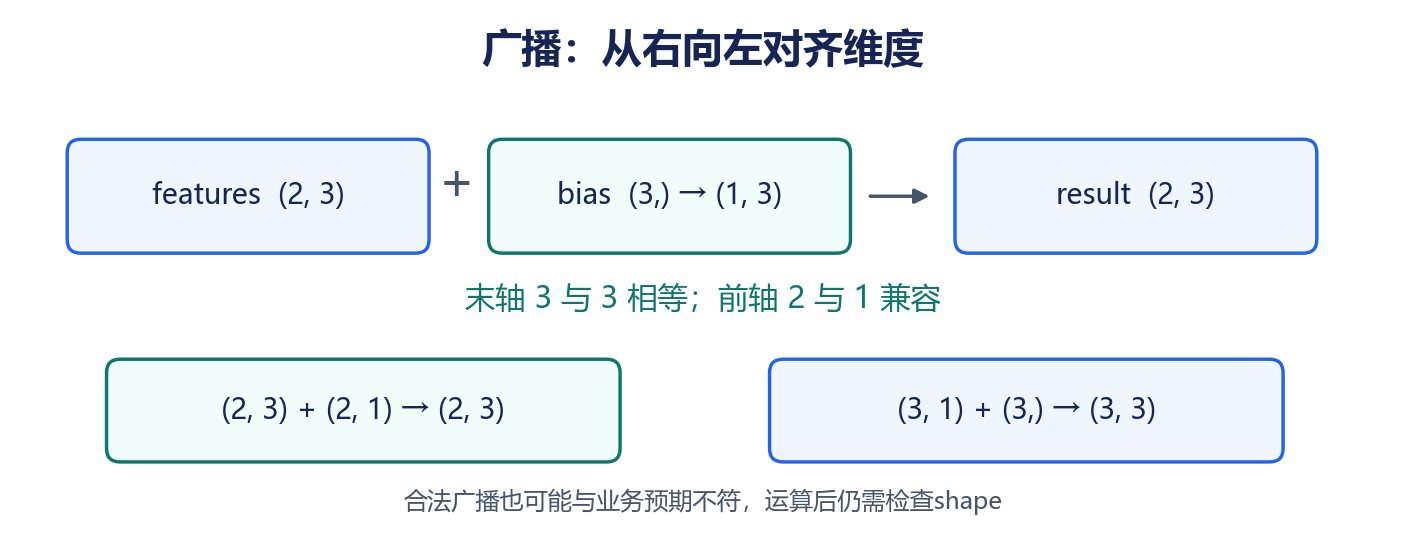

```python
features = torch.tensor([[1.0, 2.0, 3.0],
                         [4.0, 5.0, 6.0]])   # (2, 3)
feature_bias = torch.tensor([10.0, 20.0, 30.0])  # (3,)
row_bias = torch.tensor([[100.0], [200.0]])      # (2, 1)

print(features + feature_bias)
# [[11., 22., 33.], [14., 25., 36.]]
print(features + row_bias)
# [[101., 102., 103.], [204., 205., 206.]]

column = torch.tensor([[1.0], [2.0], [3.0]])  # (3, 1)
row = torch.tensor([10.0, 20.0, 30.0])         # (3,)
assert (column + row).shape == (3, 3)
```

最后一个例子合法，但若本来想逐项相加得到3个数，结果变成 `(3,3)` 就是逻辑错误。尤其做损失计算时，要检查 `(N,)` 与 `(N,1)` 是否被误广播成 `(N,N)`。


## 6. 逐元素乘、向量内积与矩阵乘

课程目录中的“点乘”容易在不同语境里指不同操作。写代码时用输出形状区分：

| 操作 | 写法 | 例子 | 结果 |
| --- | --- | --- | --- |
| 逐元素乘 | `a*b`、`torch.mul(a,b)` | `(3,)` 和 `(3,)` | `(3,)` |
| 向量内积 | `torch.dot(a,b)` | 两个等长1维向量 | 标量 `()` |
| 矩阵乘 | `A@B`、`torch.matmul(A,B)` | `(m,k)` 和 `(k,n)` | `(m,n)` |

矩阵乘中，输出第 `i` 行、第 `j` 列是A第i行与B第j列的内积：

$$C_{ij}=\sum_{r=1}^{k}A_{ir}B_{rj}.$$

```python
u = torch.tensor([1.0, 2.0, 3.0])
v = torch.tensor([4.0, 5.0, 6.0])
print(u * v)           # [4., 10., 18.]
print(torch.dot(u, v)) # 32.

A = torch.tensor([[1.0, 2.0, 3.0], [4.0, 5.0, 6.0]])
B = torch.tensor([[1.0, 0.0], [0.0, 1.0], [1.0, 1.0]])
C = A @ B
print(C)  # [[4., 5.], [10., 11.]]
assert C.shape == (2, 2)
assert C[0, 0].item() == 1 * 1 + 2 * 0 + 3 * 1
```

`torch.mm` 专门做2维矩阵乘；`torch.dot` 只接收1维向量。`matmul` 支持更一般的情况，1维向量参与时有自动补维和删维规则。


### 6.1 批量矩阵乘：只广播前面的批次轴

若 `A.shape=(batch,m,k)`、`B.shape=(batch,k,n)`，则逐批次进行矩阵乘，结果 `(batch,m,n)`。`matmul` 的前导批次维可以广播；最后两个矩阵维仍必须满足内维相等。

```python
batch_A = torch.arange(12, dtype=torch.float32).reshape(2, 2, 3)
batch_B = torch.tensor([[1.0, 0.0], [0.0, 1.0], [1.0, 1.0]])
batch_C = torch.matmul(batch_A, batch_B)
print(batch_C)
assert batch_C.shape == (2, 2, 2)
assert torch.equal(batch_C[0], batch_A[0] @ batch_B)

expanded_B = batch_B.unsqueeze(0).expand(2, -1, -1)
assert torch.equal(torch.bmm(batch_A, expanded_B), batch_C)
```

`torch.bmm` 接收两个3维张量，batch大小必须一致，不执行 `matmul` 的批次广播。`expand` 得到的视图可能多个位置指向同一存储，不要随意原地写入；这里只用于读取和计算。


## 7. 常用统计函数：dim表示沿哪个轴汇总

对 `shape=(样本数,特征数)` 的二维数据：

- `dim=0`：把样本轴汇总掉，得到每个特征的统计。
- `dim=1`：把特征轴汇总掉，得到每个样本的统计。
- 不指定 `dim`：通常汇总所有元素。

`keepdim=True` 保留被汇总轴，长度变成1，方便后续广播。

```python
data = torch.tensor([[1.0, 2.0, 3.0],
                     [4.0, 5.0, 6.0]])
print(data.sum())               # 21.
print(data.sum(dim=0))          # [5., 7., 9.]
print(data.sum(dim=1))          # [6., 15.]
feature_mean = data.mean(dim=0, keepdim=True)
row_mean = data.mean(dim=1, keepdim=True)
assert feature_mean.shape == (1, 3)
assert row_mean.shape == (2, 1)
print(data - feature_mean)
print(data - row_mean)
```

`mean` 需要浮点或复数输入，整数张量可先 `float()`。不要只背“按行/按列”，先写shape和轴的业务含义，再确定 `dim`。


### 7.1 最大值、索引、标准差和数学函数

`torch.max(x,dim=...)` 同时返回最大值和该轴内的索引；`torch.argmax` 只返回索引。索引并不自动等于业务标签，需要按标签映射解释。

```python
scores = torch.tensor([[0.1, 0.8, 0.3],
                       [0.7, 0.2, 0.4]])
max_values, max_indices = torch.max(scores, dim=1)
print(max_values, max_indices)  # [0.8, 0.7], [1, 0]
assert torch.equal(scores.argmax(dim=1), max_indices)

values = torch.tensor([1.0, 2.0, 3.0])
print(values.std(correction=0))  # 总体形式，约0.8165
print(values.std(correction=1))  # 样本形式，1.
print(torch.sqrt(values))
print(torch.exp(torch.tensor([0.0, 1.0])))
print(torch.log(torch.tensor([1.0, np.e], dtype=torch.float64)))
print(torch.abs(torch.tensor([-2.0, 3.0])))
```

`std` 默认 `correction=1`；若按总体公式处理这批数据，显式使用0。只有一个元素且 `correction=1` 时无法得到有意义的样本标准差。对数要检查输入是否大于0，实数平方根要检查输入是否非负。


## 8. 基础索引：整数取轴，切片保留轴

索引从0开始，负索引从末尾计数；切片格式为 `start:stop:step`，右端 `stop` 不包含。

```python
x = torch.arange(12).reshape(3, 4)
print(x)
# [[0,1,2,3], [4,5,6,7], [8,9,10,11]]
print(x[1])            # [4,5,6,7]，shape=(4,)
print(x[1:2])          # [[4,5,6,7]]，shape=(1,4)
print(x[:, 1])         # [1,5,9]，shape=(3,)
print(x[:, 1:2])       # [[1],[5],[9]]，shape=(3,1)
print(x[:2, 1:3])      # [[1,2],[5,6]]
print(x[-1, ::2])      # [8,10]
assert x[1, 2].item() == 6
```

`x[1]` 与 `x[1:2]` 的数值看起来相近，shape却不同。需要保留batch轴或特征轴时，使用切片或事后 `unsqueeze`。

PyTorch切片不支持负步长，例如 `x[::-1]`；需要倒序可用 `torch.flip(x,dims=[0])`。`...` 代表省略若干轴，例如3维张量 `x[...,0]` 取最后一轴的第0项。


## 9. 高级索引与布尔索引

整数列表或整数张量可以选出多个位置；多个同长度索引一起使用时，通常是**配对取元素**，不自动生成全部行列组合。

```python
x = torch.arange(12).reshape(3, 4)
selected_rows = x[[0, 2]]
paired = x[[0, 2], [1, 3]]
grid = x[[0, 2]][:, [1, 3]]
print(selected_rows)  # 第0和第2行
print(paired)         # [1, 11]
print(grid)           # [[1,3], [9,11]]
assert paired.shape == (2,)
assert grid.shape == (2, 2)

mask = x >= 8
print(x[mask])        # [8,9,10,11]，变成1维
print(x[x[:, 0] >= 4])  # 选择第1、第2行，保留列轴
```

整张矩阵同shape的布尔掩码会把匹配元素收集成1维；仅用行掩码 `x[row_mask]` 可以保留其他轴。通常基础切片返回视图，高级索引取值返回副本，后面的存储小节再验证。


### 9.1 where、比较条件和nonzero

`torch.where(condition,a,b)` 按条件在a和b之间选择，通常保留广播后的形状；`nonzero` 给出满足条件的位置。

```python
values = torch.tensor([-3.0, -1.0, 0.0, 2.0, 5.0])
valid = (values >= 0) & (values <= 3)
selected = values[valid]
replaced = torch.where(values < 0, 0.0, values)
positions = torch.nonzero(valid, as_tuple=False)
print(selected)   # [0.,2.]
print(replaced)   # [0.,0.,0.,2.,5.]
print(positions)  # [[2],[3]]
assert replaced.shape == values.shape
```

逐元素逻辑使用 `&、|、~`，每个比较表达式加括号，不能直接用Python的 `and/or` 判断多元素张量。若只想把数值限制在区间，也可用 `torch.clamp(values,min=0,max=3)`。


## 10. reshape：保持元素数，重新分组

`reshape` 改变形状，但不会按业务含义交换轴。总元素数必须一致；最多用一个 `-1`，让PyTorch根据剩余维度推导。

```python
sequence = torch.arange(12)
matrix = sequence.reshape(3, 4)
blocks = sequence.reshape(2, 2, 3)
auto_shape = sequence.reshape(2, -1)
flattened = blocks.flatten(start_dim=1)
print(matrix)
print(blocks.shape, auto_shape.shape, flattened.shape)
assert auto_shape.shape == (2, 6)
assert flattened.shape == (2, 6)
assert torch.equal(matrix.reshape(-1), sequence)
```

`12` 个元素可以变成 `(3,4)`、`(2,6)` 或 `(2,2,3)`，不能变成 `(5,3)`。是否共享存储取决于布局；`reshape` 必要时会复制，不应该依赖它一定是视图。


## 11. unsqueeze与squeeze：增删长度为1的轴

`unsqueeze(dim)` 在指定位置增加一个长度为1的轴，元素数量和数值不变。`squeeze(dim)` 只会删除该位置长度为1的轴。

```python
vector = torch.tensor([1.0, 2.0, 3.0])
row = vector.unsqueeze(0)     # (1,3)
column = vector.unsqueeze(1)  # (3,1)
print(row.shape, column.shape)

batch_one = torch.zeros(1, 3, 1)
print(batch_one.squeeze().shape)   # (3,)
print(batch_one.squeeze(2).shape)  # (1,3)，保留batch轴
print(batch_one.squeeze(1).shape)  # (1,3,1)，该轴长度不是1
assert torch.equal(column.squeeze(1), vector)
```

无参数 `squeeze()` 会删除所有长度为1的轴。当batch大小为1时，可能连batch轴也删掉。训练代码通常明确指定要删除的轴。`x[:,None]` 也可以增加轴，但初学时显式 `unsqueeze` 更便于阅读。


## 12. transpose与permute：交换轴的位置

`transpose(dim0,dim1)` 交换两个轴；`permute(...)` 给出所有轴的新顺序，每个原轴必须出现且只能出现一次。它们通常生成共享存储的视图，不按reshape的方式重新分组。

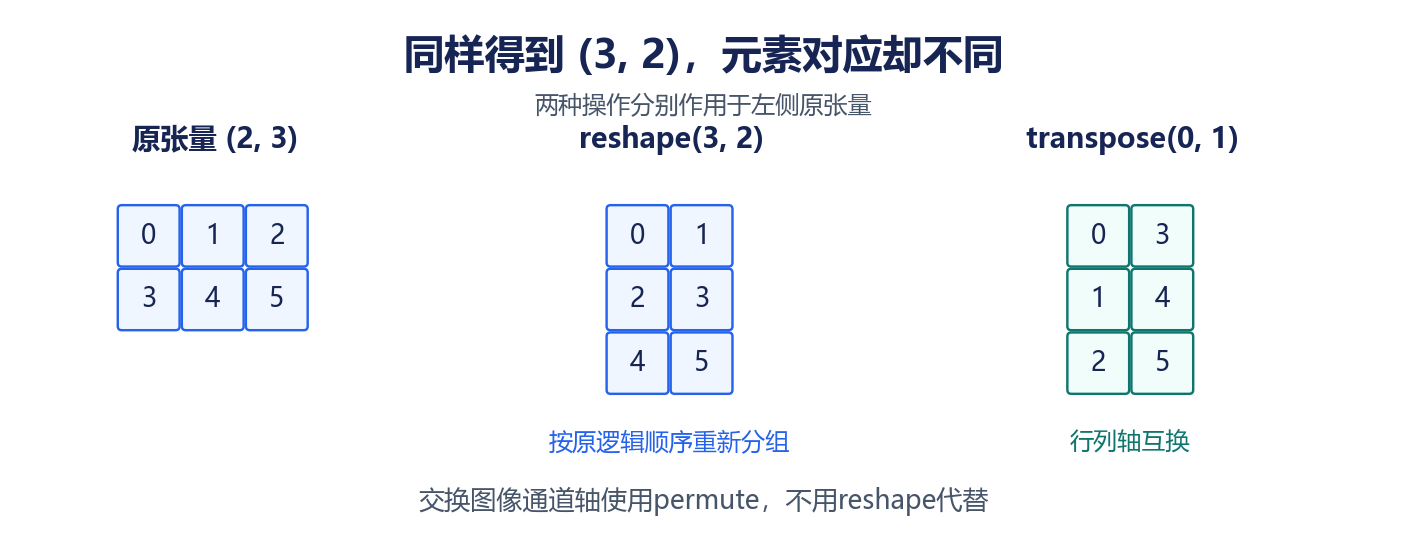

```python
matrix = torch.tensor([[0, 1, 2], [3, 4, 5]])
regrouped = matrix.reshape(3, 2)
transposed = matrix.transpose(0, 1)
print(regrouped)  # [[0,1],[2,3],[4,5]]
print(transposed) # [[0,3],[1,4],[2,5]]
assert not torch.equal(regrouped, transposed)

# 两张HWC图片：(batch, height, width, channels)
nhwc = torch.arange(24).reshape(2, 2, 2, 3)
nchw = nhwc.permute(0, 3, 1, 2)
print(nchw.shape)  # (2,3,2,2)
assert nchw[1, 2, 0, 1].item() == nhwc[1, 0, 1, 2].item()
```

`permute(0,3,1,2)` 的意思是“新轴依次使用原来的0、3、1、2号轴”。把HWC图像变成CHW，需要交换轴；直接 `reshape(C,H,W)` 通常会打乱像素与通道的对应关系。


## 13. view与contiguous：逻辑形状和存储布局

张量除shape外，还有 `stride`，表示各轴前进一步时跨过多少存储元素。`is_contiguous()` 用于判断当前布局是否满足相应连续性要求。

`view` 必须能够在现有存储与步幅上表示新形状，成功时共享存储；`reshape` 尽量返回视图，必要时复制。非连续张量并非所有 `view` 都失败，但常见的转置后直接展平会失败。

```python
base = torch.arange(6).reshape(2, 3)
transposed = base.transpose(0, 1)
print(base.stride(), transposed.stride())  # (3,1), (1,3)
assert base.is_contiguous()
assert not transposed.is_contiguous()

try:
    transposed.view(-1)
except RuntimeError:
    print("转置后的步幅不支持直接view展平")
else:
    raise AssertionError("这个示例应当拒绝直接view")

fixed = transposed.contiguous().view(-1)
convenient = transposed.reshape(-1)
print(fixed)  # [0,3,1,4,2,5]
assert torch.equal(fixed, convenient)
assert torch.equal(base.view(-1), torch.arange(6))
```

`contiguous()` 必要时复制成连续存储；已经连续时可能返回自身。它保留转置后的逻辑元素顺序，不会“撤销转置”。因此展平结果是 `[0,3,1,4,2,5]`，不是 `[0,1,2,3,4,5]`。


## 14. 视图、副本与clone、detach

“得到新变量”并不等于“数据独立”。Python赋值只是增加引用；切片、部分形状操作和detach也可能共享存储。

```python
source = torch.arange(6.0).reshape(2, 3)
basic_view = source[:, :2]
advanced_copy = source[:, [0, 1]]
independent = source.clone()

basic_view[0, 0] = -10.0
assert source[0, 0].item() == -10.0
assert advanced_copy[0, 0].item() == 0.0
assert independent[0, 0].item() == 0.0

source[:, [0, 1]] = 99.0  # 索引赋值会写回source
assert torch.all(source[:, :2] == 99.0)
```

高级索引**取值**返回副本，不代表索引**赋值**不会更新原张量。不要通过 `x[indices].add_(...)` 期待自动写回；需要更新原张量时使用索引赋值等明确操作。

| 操作 | 存储 | 自动微分关系 |
| --- | --- | --- |
| `y=x` | 同一对象 | 保留 |
| `x.clone()` | 独立副本 | 可保留到原张量的求导路径 |
| `x.detach()` | 通常共享 | 切断当前求导路径 |
| `x.detach().clone()` | 独立副本 | 切断当前求导路径 |

需要“既断开梯度，又能自由改数据”的副本时，用 `detach().clone()`。不要以 `detach` 替代复制。


## 15. cat与stack：沿已有轴合并，或增加新轴

`torch.cat` 沿已有轴拼接；除了拼接轴，其他轴的大小必须一致。`torch.stack` 增加新轴，输入张量shape必须完全相同。

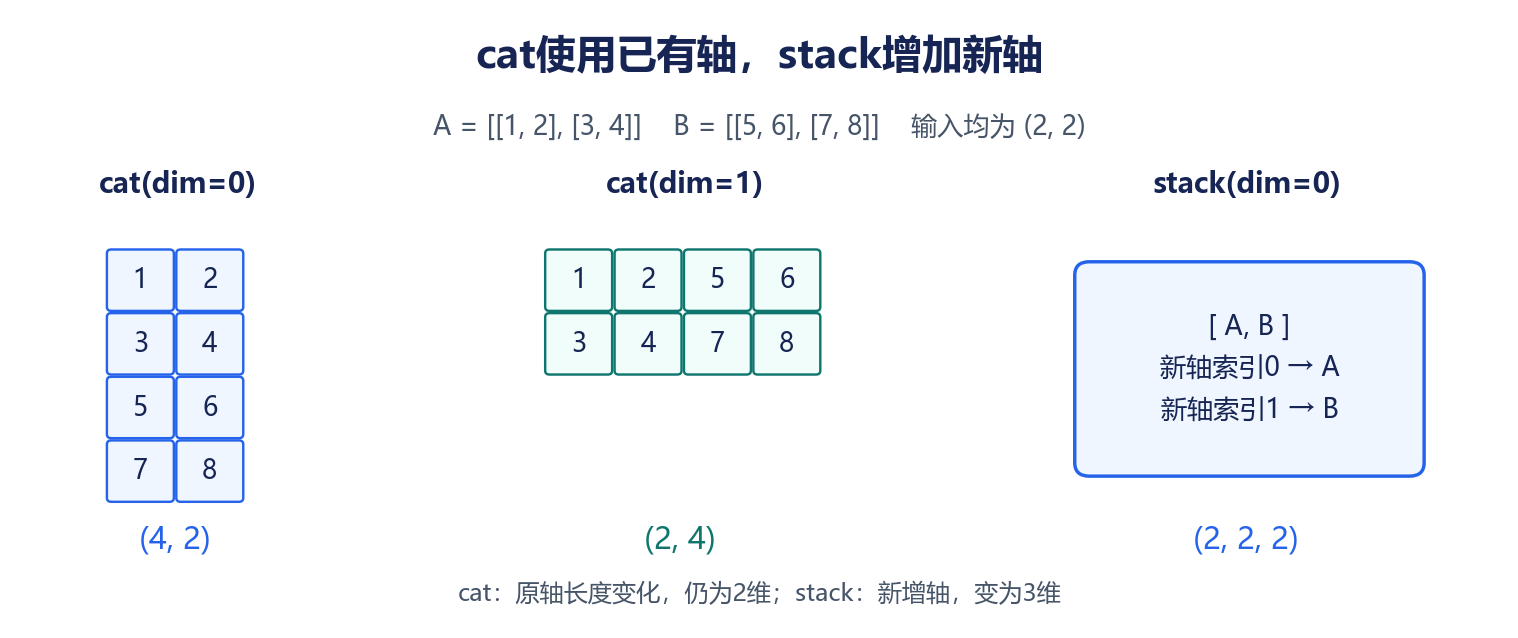

```python
A = torch.tensor([[1, 2], [3, 4]])
B = torch.tensor([[5, 6], [7, 8]])
more_samples = torch.cat([A, B], dim=0)
more_features = torch.cat([A, B], dim=1)
new_batch = torch.stack([A, B], dim=0)
print(more_samples)   # (4,2)
print(more_features)  # (2,4)
print(new_batch)      # (2,2,2)
assert more_samples.shape == (4, 2)
assert more_features.shape == (2, 4)
assert new_batch.shape == (2, 2, 2)
assert torch.equal(new_batch[0], A)
```

将两个数据批次合起来，通常用 `cat(dim=0)`；把多个同shape样本组成一个批次，通常用 `stack(dim=0)`。`cat` 不会自动增加batch轴，也不会检查样本、标签是否在业务上正确对应。


### 15.1 split与chunk：沿指定轴拆分

`split` 指定每段大小，或给出每段长度列表；`chunk` 指定希望分成多少块。`chunk` 在某些尺寸下可能返回少于请求数量的块。

```python
values = torch.arange(10)
parts = torch.split(values, 4)
custom_parts = torch.split(values, [3, 2, 5])
chunks = torch.chunk(values, 3)
print([p.tolist() for p in parts])         # 4、4、2个元素
print([p.numel() for p in custom_parts])   # [3,2,5]
print([p.numel() for p in chunks])         # [4,4,2]
assert torch.equal(torch.cat(parts), values)
assert torch.equal(torch.cat(custom_parts), values)
```

这里的拆分结果是视图，修改时仍要留意共享存储。本小节作为拼接的补充，便于后面处理批次。


## 16. 综合练习：把两张小图片组成模型输入

此例只处理形状和数值，不训练图像模型。原始数据约定为 `(N,H,W,C)`；卷积网络常用 `(N,C,H,W)`。输入是0—255的uint8数值，转为float32后缩放到0—1。

```python
images_np = np.arange(24, dtype=np.uint8).reshape(2, 2, 2, 3)
images = torch.from_numpy(images_np).to(torch.float32) / 255.0
model_input = images.permute(0, 3, 1, 2).contiguous()

one_image = model_input[0]               # (3,2,2)
one_image_batch = one_image.unsqueeze(0) # (1,3,2,2)
reassembled = torch.stack([model_input[0], model_input[1]], dim=0)
features = model_input.flatten(start_dim=1)  # (2,12)

print(model_input.shape, features.shape)
assert model_input.shape == (2, 3, 2, 2)
assert one_image_batch.shape == (1, 3, 2, 2)
assert torch.equal(reassembled, model_input)
assert model_input.min() >= 0 and model_input.max() <= 1
assert model_input[0, 2, 0, 1].item() == images[0, 0, 1, 2].item()
```

`/255` 是像素缩放，不等于减均值、除标准差的标准化。真实模型还要匹配训练时的颜色顺序、尺寸和归一化方式；本例只用人工数据验证张量操作。


## 17. 自动微分：计算的是导数

`torch.autograd` 根据前向运算构建计算图，通过链式法则计算梯度。对标量损失L和参数w，梯度 `dL/dw` 描述w在当前点微小变化时L的变化趋势。

本篇统一使用：

$$L(w)=(w-3)^2,\qquad \frac{dL}{dw}=2(w-3).$$

当 `w=0` 时，损失为9，梯度为-6。负梯度表示沿w减小方向损失上升；梯度下降更新要向相反方向移动，因此这一步应让w增加。

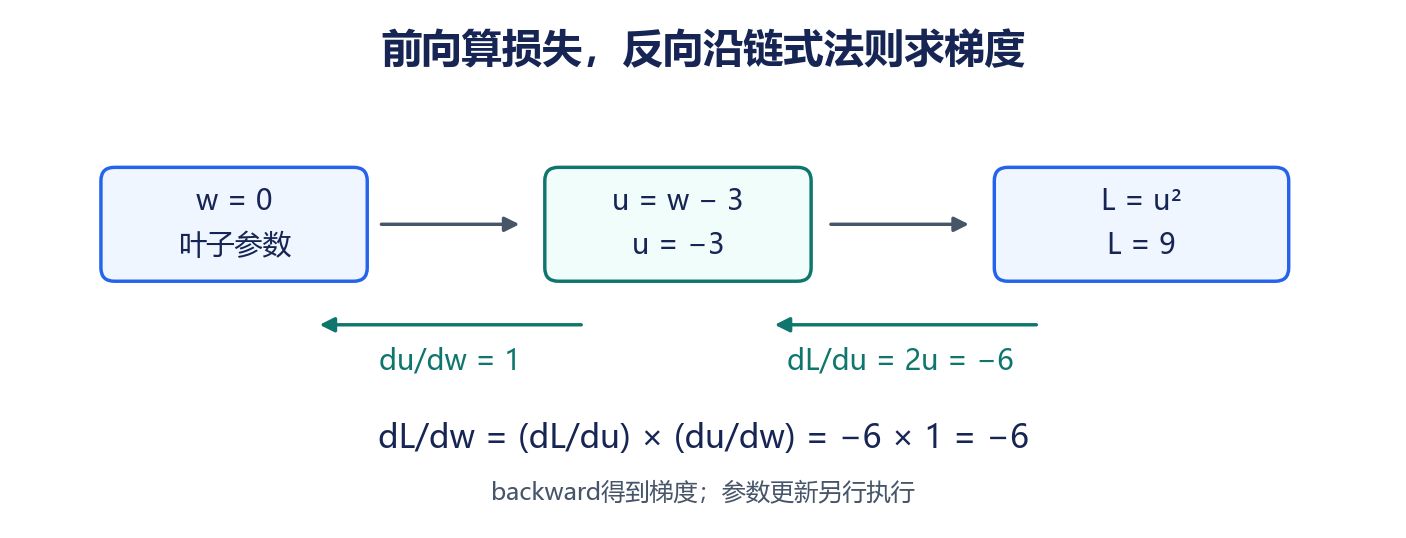

自动微分负责求梯度；**参数更新由我们或优化器执行**。梯度不是准确率，也不是损失值本身。


## 18. requires_grad、叶子张量与grad

需要求导的输入或参数，创建时设置 `requires_grad=True`。整数和布尔张量不能以这种方式求导；常见模型参数是浮点张量。

用户直接创建、需要梯度的张量通常是叶子张量；由可求导运算产生的结果通常是非叶子张量。默认情况下，反向传播会将梯度累积到需要梯度的叶子张量的 `.grad`，非叶子结果的梯度默认不保留。

```python
w = torch.tensor(0.0, requires_grad=True)
offset = w - 3.0
loss = offset.square()
print(w.requires_grad, w.is_leaf)           # True, True
print(offset.requires_grad, offset.is_leaf) # True, False
print(loss.grad_fn)                         # 由运算创建的节点
assert w.grad is None

offset.retain_grad()  # 如确实要检查中间节点的梯度，可显式保留
loss.backward()
print("loss:", loss.item())      # 9.
print("w.grad:", w.grad.item())  # -6.
print("offset.grad:", offset.grad.item())  # -6.
assert w.grad.item() == -6.0
```

`backward()` 前 `grad=None` 是正常状态，并不是梯度0。调试模型参数时先看它是否是叶子张量、是否参与损失，以及是否已执行反向传播。


## 19. 标量损失与非标量输出

对单元素输出，可以直接 `backward()`，相当于上游梯度为1。若结果有多个元素，需要明确“希望求哪个标量目标的梯度”，或者传入同shape的上游梯度。

```python
x = torch.tensor([1.0, 2.0, 3.0], requires_grad=True)
y = x.square()
total = y.sum()
total.backward()
print(x.grad)  # [2.,4.,6.]，对应sum(x²)
assert torch.equal(x.grad, torch.tensor([2.0, 4.0, 6.0]))

x2 = torch.tensor([1.0, 2.0, 3.0], requires_grad=True)
y2 = x2.square()
weights = torch.tensor([1.0, 0.0, 2.0])
y2.backward(gradient=weights)
print(x2.grad)  # [2.,0.,12.]
assert torch.equal(x2.grad, torch.tensor([2.0, 0.0, 12.0]))
```

第二个例子计算向量雅可比积，等价于对加权和 `y2[0]+2*y2[2]` 求导，并不是返回完整雅可比矩阵。入门训练时，通常先把逐样本损失用 `mean` 或 `sum` 汇总成标量；两种汇总方式会改变梯度尺度。


## 20. 梯度会累积：每轮先清零

连续反向传播会累加梯度。这个机制支持梯度累积训练，但普通的“每轮更新一次”流程必须清除上一轮梯度。

```python
p = torch.tensor(2.0, requires_grad=True)
(p.square()).backward()
print(p.grad)  # 4.
(p.square()).backward()  # 重新构建前向图，第二次梯度累加
print(p.grad)  # 8.
assert p.grad.item() == 8.0

p.grad = None
(p.square()).backward()
assert p.grad.item() == 4.0
p.grad.zero_()  # 也可原地清零，前提是grad不是None
(p.square()).backward()
assert p.grad.item() == 4.0
```

`grad=None` 与全0梯度在这里只实现相同的清理目的，内部状态并不完全一样，某些优化器对没有梯度的参数会跳过更新。

普通 `backward()` 会释放本次图中反向所需的中间数据，不要重复对同一份旧损失调用它。上例第二次使用新建的 `p.square()`，因此同时展示了**重建图**和**梯度累积**。普通训练循环每轮重新前向计算即可，通常不需要 `retain_graph=True`。


## 21. detach与no_grad的用途

`detach()` 得到脱离当前计算图的张量；`torch.no_grad()` 是上下文，期间的普通运算不记录用于反向传播的计算图。

```python
tracked = torch.tensor([2.0, 3.0], requires_grad=True)
detached_copy = tracked.detach().clone()
detached_copy[0] = -100.0
assert tracked[0].item() == 2.0
assert not detached_copy.requires_grad

with torch.no_grad():
    report = tracked.square()
assert not report.requires_grad

cloned = tracked.clone()  # clone本身不会切断求导路径
cloned.sum().backward()
assert torch.equal(tracked.grad, torch.ones_like(tracked))
```

用于记录日志时可以 `loss.item()`；导出结果时可以 `detach`；手动更新参数时用 `no_grad`。如果在真正需要求导的前向计算中过早detach，梯度路径就断了。不要用 `.data` 绕开自动微分的检查。

后续神经网络的 `model.eval()` 控制某些层的行为，`no_grad()` 控制梯度记录，两者职责不同。它们不是互相替代关系。


## 22. 更新一次参数：先算梯度，再减去学习率乘梯度

梯度下降的更新规则：

$$w_{\text{new}}=w_{\text{old}}-\eta\frac{dL}{dw}.$$

`η` 是学习率，控制步长。取 `w=0、η=0.1` 时，`w_new=0-0.1×(-6)=0.6`，新损失为 `(0.6-3)²=5.76`。

```python
w = torch.tensor(0.0, requires_grad=True)
learning_rate = 0.1

loss = (w - 3.0).square()  # 前向
loss.backward()           # 反向
old_loss = loss.item()
gradient = w.grad.item()

with torch.no_grad():     # 更新不进入下一轮的计算图
    w -= learning_rate * w.grad

new_loss = (w - 3.0).square().item()
print("梯度:", gradient)
print("新参数:", w.item())
print("损失:", old_loss, "->", new_loss)
assert w.is_leaf and w.requires_grad
assert abs(w.item() - 0.6) < 1e-6
assert abs(new_loss - 5.76) < 1e-5
assert new_loss < old_loss
```

更新后的 `w.grad` 仍是旧点算出的梯度，下一轮必须清理再重算。若在普通求导环境中直接对需要梯度的叶子参数原地更新，会触发错误；用 `no_grad` 保护更新，仍保留这个参数供下一轮求导。


## 23. 循环更新参数：清梯度→前向→反向→更新

每轮都重新构建前向图，每轮都清理之前的梯度。日志存储Python数字，避免把历史计算图长时间留在列表中。

```python
w = torch.tensor(0.0, requires_grad=True)
learning_rate = 0.1
history = []

for step in range(30):
    w.grad = None
    loss = (w - 3.0).square()
    loss.backward()
    history.append((step, w.item(), loss.item(), w.grad.item()))
    with torch.no_grad():
        w -= learning_rate * w.grad

final_loss = (w - 3.0).square().item()
for step, parameter, value, gradient in history[::5]:
    print(f"step={step:02d}, w={parameter:.4f}, loss={value:.6f}, grad={gradient:.4f}")
print(f"最终 w={w.item():.6f}, loss={final_loss:.8f}")
assert abs(w.item() - 3.0) < 0.004
assert final_loss < 2e-5
assert all(history[i + 1][2] < history[i][2] for i in range(len(history) - 1))
```

日志第0轮记录的是更新前的 `w=0、loss=9`；最终loss另行计算，属于第30次更新后的状态。不要把更新前损失和更新后参数混在一行，误以为它们来自同一次前向。

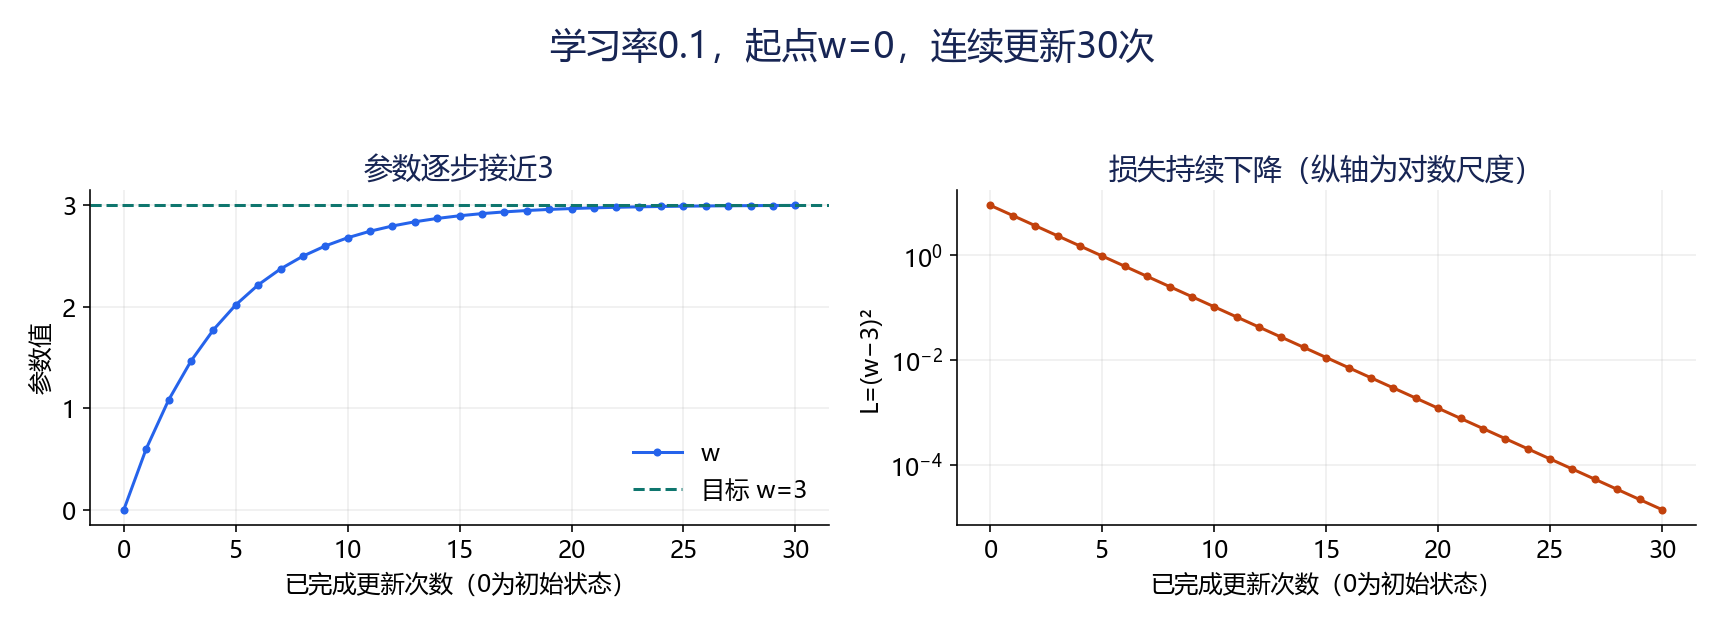

对这个特定二次函数，误差满足：

$$w_{t+1}-3=(1-2\eta)(w_t-3).$$

因此 `0<η<1` 时误差幅度收敛；`η=1` 时通常在两侧来回跳，`η>1` 时通常发散。`η=0.1` 对应每轮误差乘0.8。这个范围由本例的函数曲率决定，**不能直接推广为所有模型都用0—1的学习率**。

后续使用优化器时，同样保留这条流程：`optimizer.zero_grad() → loss计算 → loss.backward() → optimizer.step()`。


## 24. 常见错误与排查

| 表现或误区 | 原因与处理 |
| --- | --- |
| 修改NumPy后Tensor也变了 | 共享存储；需要独立副本时copy或clone |
| 需要梯度的Tensor直接numpy报错 | 先detach；若需要独立数组再copy |
| CPU数据导出后仍会影响原参数 | detach不复制，cpu也不保证复制 |
| `A*B` 结果不对 | 它是逐元素乘，矩阵乘用 `@` 或matmul |
| 合法运算却多出一个轴 | 检查广播，尤其 `(N,)` 与 `(N,1)` |
| mean对整数失败 | 先转换到浮点，再确认数据语义 |
| 取一行后batch轴消失 | 整数索引降维，可用 `i:i+1` |
| reshape后通道错乱 | 交换轴用permute，不能用reshape代替 |
| 转置后view展平报错 | 步幅不兼容；用reshape或contiguous后view |
| batch=1时squeeze删掉batch | 指定要删除的轴 |
| cat和stack输出维度相差1 | cat沿已有轴，stack增加新轴 |
| 参数grad一直是None | 检查requires_grad、叶子状态、损失是否连接、是否backward |
| 第二轮梯度越来越大 | 检查是否忘记清零；累积不一定是模型问题 |
| 多元素输出不能直接backward | 先汇总成标量，或给同shape上游梯度 |
| 第二次对旧loss反向报错 | 普通循环重建前向图，不依赖保留旧图 |
| 更新参数时报叶子原地运算错误 | 把更新放在no_grad中 |
| loss.item后无法backward | 已成为Python数字，求导必须用原Tensor损失 |
| 学习率过大，loss上升 | 观察更新前后损失，调小步长，检查梯度尺度 |

排查顺序：先打印 `shape/dtype/device`，再检查内存共享与索引，最后查看 `requires_grad/is_leaf/grad`。不要靠反复reshape或detach消除报错；它们可能同时隐藏业务错误或切断梯度。


## 25. 练习与参考答案

先尝试口算shape和数值，再运行核对。

1. `(4,3)` 加 `(3,)` 输出什么？`(4,3)` 加 `(4,)` 呢？  
   **答：**前者 `(4,3)`；后者最右侧3与4不兼容，报错。
2. 12个元素能否 `reshape(2,-1)`？能否 `reshape(5,-1)`？  
   **答：**前者变成 `(2,6)`；后者无法整除，报错。
3. `x.shape=(1,3,1)`，`x.squeeze()` 和 `x.squeeze(2)` 的shape分别是多少？  
   **答：**`(3,)` 与 `(1,3)`。
4. 两个 `(2,3)` 张量，分别 `cat(dim=0)`、`cat(dim=1)`、`stack(dim=0)`？  
   **答：**`(4,3)`、`(2,6)`、`(2,2,3)`。
5. `L(w)=(w-3)²`，当前w=1、学习率0.1，一步之后w是多少？  
   **答：**梯度-4，更新为 `1-0.1×(-4)=1.4`；新损失2.56。
6. 要得到脱离计算图且可独立修改的Tensor副本，如何写？  
   **答：**`x.detach().clone()`。
7. 两个索引列表 `x[[0,2],[1,3]]` 是2个元素还是2×2网格？  
   **答：**配对选择2个元素；可用两次索引选行列组成网格。

```python
first = torch.zeros(2, 3)
second = torch.ones(2, 3)
assert torch.cat([first, second], dim=0).shape == (4, 3)
assert torch.cat([first, second], dim=1).shape == (2, 6)
assert torch.stack([first, second], dim=0).shape == (2, 2, 3)

exercise_w = torch.tensor(1.0, requires_grad=True)
exercise_loss = (exercise_w - 3.0).square()
exercise_loss.backward()
with torch.no_grad():
    exercise_w -= 0.1 * exercise_w.grad
assert abs(exercise_w.item() - 1.4) < 1e-6
assert abs((exercise_w - 3.0).square().item() - 2.56) < 1e-5
print("练习中的形状与更新数值已核对")
```


## 26. 操作速查

| 需求 | 常见写法 | 注意点 |
| --- | --- | --- |
| NumPy共享转Tensor | `torch.from_numpy(arr)` | 修改会互相影响 |
| Tensor导出独立NumPy | `x.detach().cpu().numpy().copy()` | 与梯度链路分离 |
| 单个Python数字 | `x.item()` | 仅单元素 |
| 逐元素乘 | `x*y` | 可广播 |
| 1维向量内积 | `torch.dot(x,y)` | 返回标量 |
| 矩阵乘 | `A@B` | 内维一致 |
| 保留统计轴 | `x.mean(dim=0,keepdim=True)` | 便于广播 |
| 布尔选择 | `x[mask]` | 同shape掩码通常展平 |
| 条件替换 | `torch.where(mask,a,b)` | 保留广播后shape |
| 重新分组 | `x.reshape(...)` | 元素总数不变 |
| 增删单例轴 | `unsqueeze/squeeze(dim)` | 无参数squeeze会删除所有单例轴 |
| 交换两个轴 | `transpose(a,b)` | 常得到非连续视图 |
| 调整全部轴顺序 | `permute(...)` | 每个原轴恰好出现一次 |
| 连续化后view | `x.contiguous().view(...)` | 必要时复制 |
| 沿已有轴拼接 | `torch.cat([...],dim=...)` | 其他轴一致 |
| 新建轴叠放 | `torch.stack([...],dim=...)` | 输入shape完全一致 |
| 标量反向 | `loss.backward()` | 梯度默认累积 |
| 清理手动参数梯度 | `parameter.grad=None` | 下一轮反向重新计算 |
| 手动参数更新 | `with torch.no_grad(): ...` | 参数仍可参与下一轮求导 |

本篇的核心是把数据从“能创建”推进到“能正确进入计算”：shape含义明确，运算方式正确，内存关系可控，梯度流程完整。


## 27. 课程目录与来源范围

本篇核对的16个视频标题如下：

| 编号 | day02视频文件 | 对应笔记 |
| --- | --- | --- |
| 01 | 今日内容大纲介绍 | 学习路线 |
| 02 | 张量和Numpy之间相互转换 | 第2—3节 |
| 03 | 张量的基本运算 | 第4—5节 |
| 04 | 张量点乘和矩阵乘法 | 第6节 |
| 05 | 张量的常用运算函数 | 第7节 |
| 06 | 张量的索引操作(上) | 第8节 |
| 07 | 张量的索引操作(下) | 第9节 |
| 08 | 上午内容回顾 | 练习与速查 |
| 09 | 张量的形状操作_reshape函数 | 第10节 |
| 10 | 张量的形状操作_unsqueeze和squeeze函数 | 第11节 |
| 11 | 张量的形状操作_transpose和permute函数 | 第12节 |
| 12 | 张量的形状操作_view和contiguous函数 | 第13—14节 |
| 13 | 张量的拼接操作 | 第15—16节 |
| 14 | 自动微分模块_介绍 | 第17—21节 |
| 15 | 自动微分模块案例_更新一次参数 | 第22节 |
| 16 | 自动微分模块案例_循环更新参数 | 第23节 |

本篇以视频标题确认主题范围，未读取教师压缩包正文，也未逐段转录视频。批量矩阵乘、split/chunk、图片形状练习和一元目标函数是为理解主题补充的独立示例，不声称与视频中的具体演示相同。

延伸查阅：[PyTorch张量文档](https://docs.pytorch.org/docs/stable/tensors.html)、[NumPy转换接口](https://docs.pytorch.org/docs/stable/generated/torch.from_numpy.html)、[自动微分入门](https://docs.pytorch.org/tutorials/beginner/basics/autogradqs_tutorial.html)、[autograd文档](https://docs.pytorch.org/docs/stable/autograd.html)。本篇所述API行为以实际CPU运行核对，链接用于进一步查阅。

图均为本篇自绘并内嵌，没有单独图片文件依赖。下一篇按day03继续：自动微分应用、线性回归、神经网络与激活函数。

本次验证环境：Python 3.13.7、PyTorch 2.14.1+cpu、NumPy 2.3.3、CPU。顺序运行 27 段Python代码通过，5张图片均为Notebook附件；数值、内存共享、错误条件和30次参数更新均已核对。本篇没有CUDA代码分支，也未在GPU上验证。
